150 scenes over 3.5 yr   corr(t, SZA) = -0.073
true fractional drift b/a      = -0.385 %/yr
true directional sens. d/c     = 0.2118


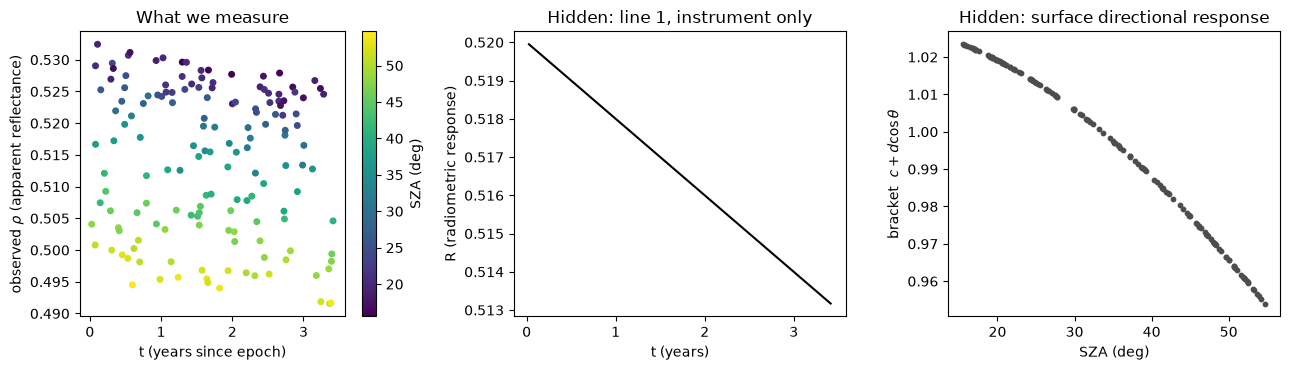

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# USER-CONFIGURABLE INPUTS
# ------------------------------------------------------------------
RNG_SEED  = 42
N_SCENES  = 150
T_SPAN_YR = 3.5          # mission length, years since t = 0 epoch
SZA_MIN, SZA_MAX = 15.0, 55.0

# True (hidden) physical parameters -- the fit must recover these
A_TRUE = 0.520           # line 1: radiometric response at t = 0
B_TRUE = -0.002          # line 1: drift slope, response units per year
C_TRUE = 0.85            # bracket: baseline directional factor
D_TRUE = 0.18            # bracket: directional sensitivity

NOISE_FRAC = 0.003       # 0.3 % multiplicative noise (atmosphere, retrieval)

# ------------------------------------------------------------------
# Generate one synthetic scene table (one row per acquisition)
# ------------------------------------------------------------------
rng = np.random.default_rng(RNG_SEED)

t   = np.sort(rng.uniform(0.0, T_SPAN_YR, N_SCENES))       # decimal years
sza = rng.uniform(SZA_MIN, SZA_MAX, N_SCENES)              # degrees, uncorrelated with t
g   = np.cos(np.radians(sza))                              # geometry regressor

R       = A_TRUE + B_TRUE * t                              # line 1 (never observed)
bracket = C_TRUE + D_TRUE * g                              # surface directional response
rho     = bracket * R * (1.0 + NOISE_FRAC * rng.standard_normal(N_SCENES))  # line 2 + noise

print(f"{N_SCENES} scenes over {T_SPAN_YR} yr   "
      f"corr(t, SZA) = {np.corrcoef(t, sza)[0,1]:+.3f}")
print(f"true fractional drift b/a      = {100*B_TRUE/A_TRUE:+.3f} %/yr")
print(f"true directional sens. d/c     = {D_TRUE/C_TRUE:.4f}")

# ------------------------------------------------------------------
# Display: what the sensor reports, and the two hidden ingredients
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

sc = axes[0].scatter(t, rho, c=sza, cmap="viridis", s=16)
axes[0].set_xlabel("t (years since epoch)")
axes[0].set_ylabel(r"observed $\rho$ (apparent reflectance)")
axes[0].set_title("What we measure")
plt.colorbar(sc, ax=axes[0], label="SZA (deg)")

axes[1].plot(t, R, "k-", lw=1.5)
axes[1].set_xlabel("t (years)")
axes[1].set_ylabel("R (radiometric response)")
axes[1].set_title("Hidden: line 1, instrument only")

axes[2].scatter(sza, bracket, s=10, color="0.3")
axes[2].set_xlabel("SZA (deg)")
axes[2].set_ylabel(r"bracket  $c + d\cos\theta$")
axes[2].set_title("Hidden: surface directional response")

fig.tight_layout()
plt.show()

  coef     fitted    +/- SE  true (product)
 alpha    0.44144   0.00169         0.44200
  beta   -0.00162   0.00086        -0.00170
 gamma    0.09471   0.00211         0.09360
   eta   -0.00071   0.00107        -0.00036

residual RMSE = 0.30 % of mean signal (noise injected: 0.30 %)


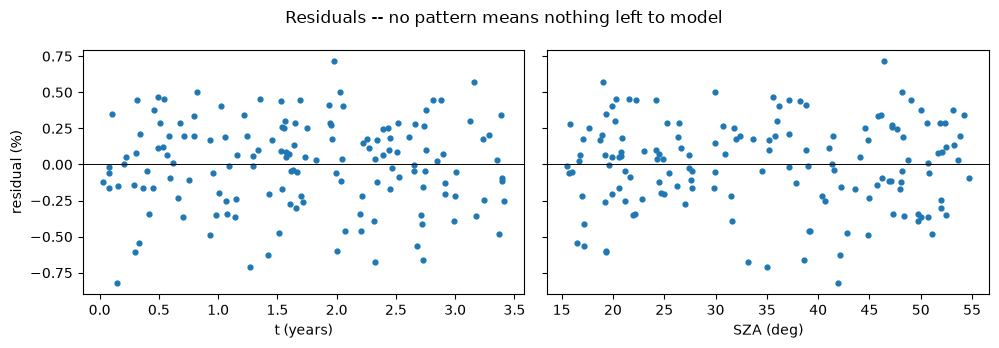

In [7]:
# ------------------------------------------------------------------
# Line 3: expand the product, build the design matrix, solve
# ------------------------------------------------------------------
# (c + d*g)(a + b*t)  =  ca + cb*t + da*g + db*g*t
#                     =  alpha + beta*t + gamma*g + eta*g*t
#
# One row per scene, one column per coefficient.

X = np.column_stack([
    np.ones(N_SCENES),   # alpha : baseline
    t,                   # beta  : time
    g,                   # gamma : geometry
    g * t,               # eta   : geometry x time
])

coef, _, _, _ = np.linalg.lstsq(X, rho, rcond=None)
alpha, beta, gamma, eta = coef

# Analytical standard errors (valid here: independent noise by construction)
resid = rho - X @ coef
dof   = N_SCENES - X.shape[1]
cov   = (resid @ resid / dof) * np.linalg.inv(X.T @ X)
se    = np.sqrt(np.diag(cov))

truth = {"alpha": C_TRUE * A_TRUE, "beta": C_TRUE * B_TRUE,
         "gamma": D_TRUE * A_TRUE, "eta":  D_TRUE * B_TRUE}

print(f"{'coef':>6} {'fitted':>10} {'+/- SE':>9} {'true (product)':>15}")
for name, f, s in zip(truth, coef, se):
    print(f"{name:>6} {f:>10.5f} {s:>9.5f} {truth[name]:>15.5f}")

rmse_pct = 100 * np.sqrt(np.mean(resid**2)) / rho.mean()
print(f"\nresidual RMSE = {rmse_pct:.2f} % of mean signal "
      f"(noise injected: {100*NOISE_FRAC:.2f} %)")

# ------------------------------------------------------------------
# Residual diagnostics: structureless = the model form is adequate
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, x, xlabel in [(axes[0], t, "t (years)"), (axes[1], sza, "SZA (deg)")]:
    ax.scatter(x, 100 * resid / rho, s=12)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("residual (%)")
fig.suptitle("Residuals -- no pattern means nothing left to model")
fig.tight_layout()
plt.show()

In [8]:
print(np.linalg.inv(X.T @ X))

[[ 1.16071558 -0.50961196 -1.43359507  0.62952074]
 [-0.50961196  0.30251939  0.62923035 -0.37142883]
 [-1.43359507  0.62923035  1.81400864 -0.79670199]
 [ 0.62952074 -0.37142883 -0.79670199  0.46739036]]
